# Pricing and hedging a worst-of autocallable note

A worst-of autocallable is one of the most widely sold structured products. This notebook prices one on the
**S&P 500, Euro Stoxx 50 and Nikkei 225** with Monte Carlo, explains what drives its value, shows the issuer's margin
and the fair coupon, and looks at how the desk would hedge it.

**The note** (notional 100, issued at 100):
- 3 years, observed every quarter (12 dates). Performance of each index = level / starting level; the note looks only
  at the **worst** of the three.
- **Autocall:** on any observation date, if the worst performance is at or above 100%, the note repays 100 plus the
  coupon and ends.
- **Coupon:** paid on a date if the worst performance is at or above 70%; missed coupons are paid later if the
  condition is met again (memory).
- **Capital at risk:** if the note is never called and the worst performance at maturity is below 60%, the investor
  receives 100 x worst performance; otherwise 100.

All numbers below are computed when the notebook runs, from market data cached in `data/`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "src"))
from autocall import market as M

ACCENT, GREYS = "#1F4E79", ["#7F8C9A", "#B8C2CC"]
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 11, "font.size": 9.5})
pct = lambda x, d=1: "–" if pd.isna(x) else f"{100 * x:.{d}f}%"  # noqa: E731

## 1. Market data

Daily closes from Yahoo Finance for the three indices, the 13-week US Treasury bill yield (for discounting) and the
dividend yields of an ETF tracking each index. The data are cached in `data/` with the date they were fetched.

In [2]:
prices, meta = M.load_prices(), M.load_meta()
closes = M.common_closes(prices)
rets = M.log_returns(closes)
print(f"Fetched on {meta['fetched_on']} from {meta['source']}")
print(f"Prices from {closes.index[0]:%d-%b-%Y} to {closes.index[-1]:%d-%b-%Y} (as of date for pricing)")
M.calendar_gaps(prices)

Fetched on 2026-11-05 from Yahoo Finance via yfinance
Prices from 01-Oct-2021 to 04-Nov-2026 (as of date for pricing)


,own trading days,missing on union calendar,days kept (common)
S&P 500,1279,46,1173
Euro Stoxx 50,1281,44,1173
Nikkei 225,1244,81,1173


**Holidays differ.** The US, Europe and Japan close on different days, so the union calendar has gaps. Volatility and
correlation use only days when all three markets traded; a return then simply spans the holiday.

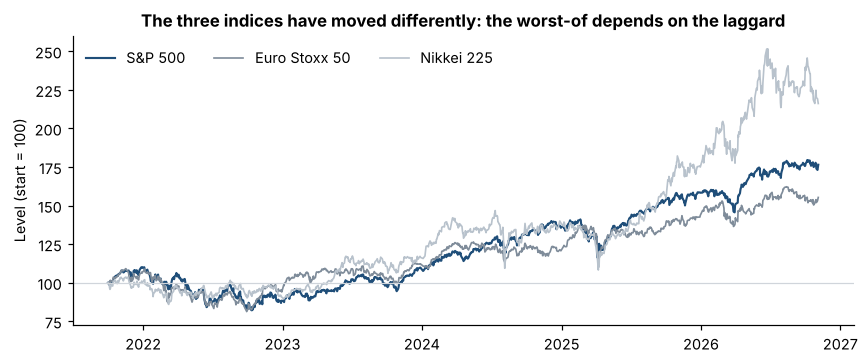

In [3]:
fig, ax = plt.subplots(figsize=(8, 3.4))
rebased = 100 * closes / closes.iloc[0]
for col, c in zip(rebased.columns, [ACCENT] + GREYS):
    ax.plot(rebased.index, rebased[col], color=c, lw=1.4 if c == ACCENT else 1.1, label=col)
ax.axhline(100, color="#D0D5DB", lw=0.8)
ax.set(title="The three indices have moved differently: the worst-of depends on the laggard",
       ylabel="Level (start = 100)")
ax.legend(frameon=False, ncol=3, loc="upper left")
plt.tight_layout()

### Volatility

Three estimates from daily log returns, and one from the option market:
- **historical (full sample)** and **historical (last year)**: annualised standard deviation;
- **EWMA** (RiskMetrics, lambda 0.94): weights recent days more, so it reacts fast;
- **implied** (S&P 500 only): read from at-the-money S&P 500 options expiring close to the note's maturity.

In [4]:
vols = pd.DataFrame({
    "historical, full sample": M.historical_vol(rets),
    "historical, last year": M.historical_vol(rets, M.TRADING_DAYS),
    "EWMA (latest)": M.ewma_vol(rets).iloc[-1],
})
imp = meta.get("spx_implied")
if imp:
    vols.loc["S&P 500", f"implied, {imp['years']:.1f}y ATM"] = imp["atm_iv"]
vols.map(pct).rename_axis("annualised volatility")

,"historical, full sample","historical, last year",EWMA (latest),"implied, 3.1y ATM"
annualised volatility,,,,
S&P 500,17.3%,13.2%,11.8%,19.5%
Euro Stoxx 50,18.0%,15.4%,13.7%,–
Nikkei 225,24.2%,29.8%,25.8%,–


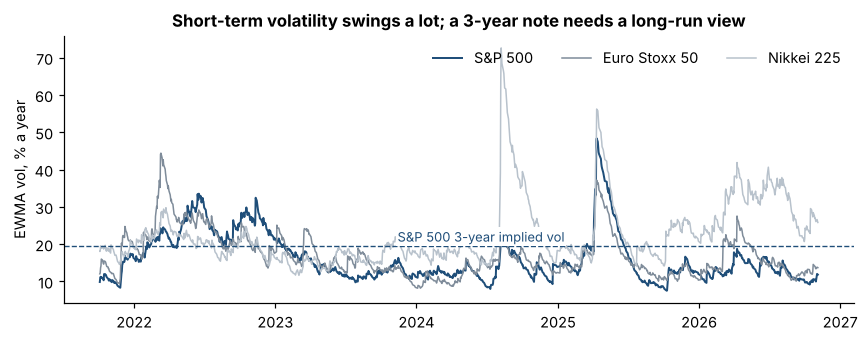

In [5]:
ew = M.ewma_vol(rets)
fig, ax = plt.subplots(figsize=(8, 3.2))
for col, c in zip(ew.columns, [ACCENT] + GREYS):
    ax.plot(ew.index, 100 * ew[col], color=c, lw=1.3 if c == ACCENT else 1.0, label=col)
if imp:
    ax.axhline(100 * imp["atm_iv"], color=ACCENT, ls="--", lw=0.9)
    ax.text(ew.index[int(len(ew) * 0.42)], 100 * imp["atm_iv"] + 1.2, f"S&P 500 {imp['years']:.0f}-year implied vol",
            color=ACCENT, fontsize=8.5, bbox=dict(fc="white", ec="none", pad=1))
ax.set(title="Short-term volatility swings a lot; a 3-year note needs a long-run view", ylabel="EWMA vol, % a year")
ax.legend(frameon=False, ncol=3, loc="upper right")
plt.tight_layout()

In [6]:
spx = vols.loc["S&P 500"]
print(f"S&P 500: EWMA {spx['EWMA (latest)']:.1%}, full-sample historical {spx['historical, full sample']:.1%}"
      + (f", {imp['years']:.1f}-year implied {imp['atm_iv']:.1%}" if imp else ""))
print("Pricing default: full-sample historical vol. It is the closest of the history-based estimates to the long-dated")
print("implied vol, while the latest EWMA reflects only the last few calm or stressed weeks.")

S&P 500: EWMA 11.8%, full-sample historical 17.3%, 3.1-year implied 19.5%
Pricing default: full-sample historical vol. It is the closest of the history-based estimates to the long-dated
implied vol, while the latest EWMA reflects only the last few calm or stressed weeks.


### Correlation, and why the closing times matter

The worst-of payoff depends heavily on how the indices move together. Tokyo closes before Europe opens, and Europe
closes before New York does, so news that hits the US on day *t* reaches the Nikkei only on day *t + 1*. Same-day
returns therefore understate the true co-movement. Longer return horizons fix most of this.

In [7]:
pairs = [("S&P 500", "Euro Stoxx 50"), ("S&P 500", "Nikkei 225"), ("Euro Stoxx 50", "Nikkei 225")]
corr_tab = pd.DataFrame({f"{h}-day returns": [M.correlation(rets, h).loc[a, b] for a, b in pairs] for h in (1, 2, 5)},
                        index=[f"{a} / {b}" for a, b in pairs])
corr_tab.round(2)

,1-day returns,2-day returns,5-day returns
S&P 500 / Euro Stoxx 50,0.50,0.60,0.70
S&P 500 / Nikkei 225,0.16,0.45,0.62
Euro Stoxx 50 / Nikkei 225,0.33,0.48,0.60


In [8]:
ll = M.lead_lag_correlation(rets, "Nikkei 225", "S&P 500")
print(f"Nikkei vs S&P 500, same day: {ll['same day']:.2f}; Nikkei on the next day vs S&P 500: {ll['Nikkei 225 next day']:.2f}")
print("The Nikkei reacts a day later to US news, so the model uses weekly (5-day) return correlations.")

Nikkei vs S&P 500, same day: 0.16; Nikkei on the next day vs S&P 500: 0.47
The Nikkei reacts a day later to US news, so the model uses weekly (5-day) return correlations.


In [9]:
snap = M.snapshot()
ok, eig = M.is_positive_definite(snap.corr)
print(f"Correlation matrix used for pricing (weekly returns, full sample). Eigenvalues {np.round(eig, 3)}:",
      "positive definite, so a Cholesky factor exists." if ok else "NOT positive definite.")
pd.DataFrame(snap.corr, index=snap.names, columns=snap.names).round(3)

Correlation matrix used for pricing (weekly returns, full sample). Eigenvalues [0.299 0.422 2.279]: positive definite, so a Cholesky factor exists.


,S&P 500,Euro Stoxx 50,Nikkei 225
S&P 500,1.000,0.700,0.616
Euro Stoxx 50,0.700,1.000,0.601
Nikkei 225,0.616,0.601,1.000


### Rates and dividends

In [10]:
inputs = pd.DataFrame({"spot (as of)": [f"{x:,.2f}" for x in snap.spot], "vol": [pct(v) for v in snap.vol],
                       "dividend yield": [pct(v, 2) for v in snap.div]}, index=snap.names)
inputs["dividend source"] = [f"{v['etf']} trailing yield" for v in meta["dividend_yields"].values()]
print(f"USD rate: {snap.rate:.2%} continuously compounded, from the 13-week T-bill yield on {snap.notes['rate_date']}")
inputs

USD rate: 3.95% continuously compounded, from the 13-week T-bill yield on 2026-11-04


,spot (as of),vol,dividend yield,dividend source
S&P 500,"7,688.62",17.3%,1.00%,SPY trailing yield
Euro Stoxx 50,"6,265.71",18.0%,2.81%,FEZ trailing yield
Nikkei 225,"62,188.63",24.2%,1.17%,1321.T trailing yield


## 2. Pricing the note

### Model and assumptions

Each assumption is a deliberate simplification; the right-hand column says what a trading desk would use instead.

In [11]:
from autocall import mc
from autocall import blackscholes as bs
from autocall.note import TermSheet

ts = TermSheet()
mkt = mc.Market.from_snapshot(snap)
assumptions = pd.DataFrame([
    ("Dynamics", "Correlated geometric Brownian motion, risk-neutral drift r - q", "Local or stochastic volatility calibrated to the smile"),
    ("Volatility", f"Constant, full-sample historical ({', '.join(pct(v) for v in snap.vol)})", "Implied volatility surface per index"),
    ("Correlation", "Constant, from weekly returns (closing-time effect removed)", "Implied correlation from quanto / dispersion markets, plus a reserve"),
    ("Rates", f"Flat {pct(snap.rate, 2)} (13-week T-bill)", "USD SOFR discount curve"),
    ("Dividends", "Flat yields from index ETFs", "Dividend futures and forecast dividend schedules"),
    ("Currency", "Ignored: no quanto adjustment for paying USD on EUR and JPY indices", "Quanto drift adjustment using FX vol and FX-index correlation"),
    ("Dates", "Observations every 0.25 years, payment on the observation date", "Actual calendars, settlement lags, ACT/360 or ACT/365"),
    ("Monte Carlo", f"{mc.DEFAULT_PATHS:,} paths, antithetic, seed {mc.DEFAULT_SEED}, exact steps on observation dates", "More paths, quasi-random numbers, control variates"),
], columns=["Item", "This notebook", "On a desk"]).set_index("Item")
assumptions

,This notebook,On a desk
Item,,
Dynamics,"Correlated geometric Brownian motion, risk-neu...",Local or stochastic volatility calibrated to t...
Volatility,"Constant, full-sample historical (17.3%, 18.0%...",Implied volatility surface per index
Correlation,"Constant, from weekly returns (closing-time ef...",Implied correlation from quanto / dispersion m...
Rates,Flat 3.95% (13-week T-bill),USD SOFR discount curve
Dividends,Flat yields from index ETFs,Dividend futures and forecast dividend schedules
Currency,Ignored: no quanto adjustment for paying USD o...,Quanto drift adjustment using FX vol and FX-in...
Dates,"Observations every 0.25 years, payment on the ...","Actual calendars, settlement lags, ACT/360 or ..."
Monte Carlo,"100,000 paths, antithetic, seed 7, exact steps...","More paths, quasi-random numbers, control vari..."


In [12]:
terms = pd.Series({
    "Underlyings": ", ".join(snap.names) + " (worst-of)",
    "Tenor": f"{ts.tenor_years:.0f} years, {ts.n_obs} quarterly observations",
    "Autocall trigger": pct(ts.autocall_trigger, 0),
    "Coupon": f"{pct(ts.coupon_pa, 1)} a year ({pct(ts.coupon_per_period, 1)} a quarter), barrier {pct(ts.coupon_barrier, 0)}, "
              + ("with memory" if ts.memory else "no memory"),
    "Capital protection barrier": f"{pct(ts.ki_barrier, 0)} at maturity only",
    "Notional / issue price": f"{ts.notional:.0f} / {ts.issue_price:.0f}",
}, name="Term sheet")
terms.to_frame()

,Term sheet
Underlyings,"S&P 500, Euro Stoxx 50, Nikkei 225 (worst-of)"
Tenor,"3 years, 12 quarterly observations"
Autocall trigger,100%
Coupon,"8.0% a year (2.0% a quarter), barrier 70%, wit..."
Capital protection barrier,60% at maturity only
Notional / issue price,100 / 100


### Validation: the engine must reproduce Black-Scholes

The same path generator that prices the note prices a European call and a digital (pays 1 if above the strike) on one
asset, where the exact answer is known. The difference should be within a few standard errors.

In [13]:
m1 = mc.Market(vol=np.array([snap.vol[0]]), corr=np.eye(1), rate=snap.rate, div=np.array([snap.div[0]]))
rows = []
for K in (0.8, 1.0, 1.2):
    for name, payoff, exact in [
        ("call", lambda s, K=K: np.maximum(s[:, 0] - K, 0), bs.call(1, K, ts.tenor_years, m1.rate, m1.div[0], m1.vol[0])),
        ("digital", lambda s, K=K: (s[:, 0] > K).astype(float), bs.digital_call(1, K, ts.tenor_years, m1.rate, m1.div[0], m1.vol[0])),
    ]:
        est, se = mc.european_mc(payoff, m1, ts.tenor_years)
        rows.append((name, pct(K, 0), exact, est, se, (est - exact) / se))
val = pd.DataFrame(rows, columns=["payoff", "strike", "Black-Scholes", "Monte Carlo", "std error", "difference (std errors)"])
print(f"S&P 500 inputs, {ts.tenor_years:.0f}-year expiry; largest difference "
      f"{val['difference (std errors)'].abs().max():.1f} standard errors.")
val.round({"Black-Scholes": 5, "Monte Carlo": 5, "std error": 5, "difference (std errors)": 2})

S&P 500 inputs, 3-year expiry; largest difference 2.0 standard errors.


,payoff,strike,Black-Scholes,Monte Carlo,std error,difference (std errors)
0,call,80%,0.27897,0.27858,0.00042,-0.93
1,digital,80%,0.72176,0.72219,0.00096,0.44
2,call,100%,0.15672,0.15615,0.00053,-1.07
3,digital,100%,0.49507,0.49635,0.00064,2.01
4,call,120%,0.07961,0.07915,0.00048,-0.95
5,digital,120%,0.28579,0.28502,0.00095,-0.81


### The price

In [14]:
res = mc.price(ts, mkt)
print(f"Fair value: {res.price:.2f} per 100 notional (standard error {res.stderr:.3f}; "
      f"95% interval {res.ci95[0]:.2f} to {res.ci95[1]:.2f}; {res.n_paths:,} paths)")
print(f"Issued at {ts.issue_price:.0f}: the issuer keeps about {ts.issue_price - res.price:.2f} of every 100 as margin "
      "and hedging budget, before costs.")
pd.Series({"Present value of coupons": res.pv_coupons, "Present value of the redemption": res.pv_redemption,
           "Fair value": res.price}).round(2).to_frame("per 100 notional")

Fair value: 99.03 per 100 notional (standard error 0.051; 95% interval 98.93 to 99.13; 100,000 paths)
Issued at 100: the issuer keeps about 0.97 of every 100 as margin and hedging budget, before costs.


,per 100 notional
Present value of coupons,9.69
Present value of the redemption,89.35
Fair value,99.03


Standard error at 100,000 paths: 0.0510 with antithetic paths, 0.0521 without. The gain is small because the payoff jumps at the barriers; error falls with the square root of the number of paths.


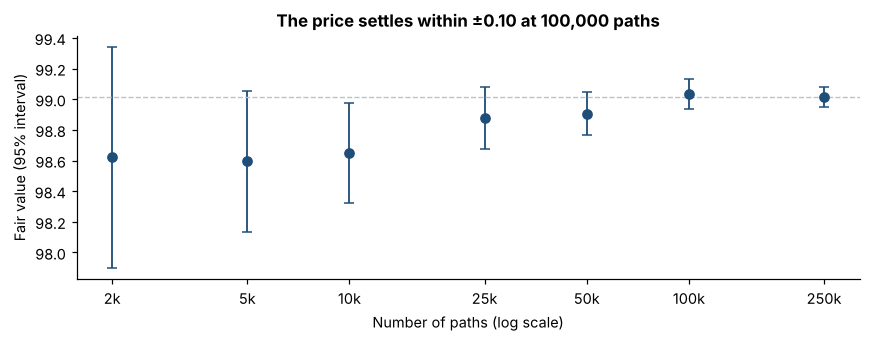

In [15]:
ns = [2_000, 5_000, 10_000, 25_000, 50_000, 100_000, 250_000]
conv = [mc.price(ts, mkt, n_paths=n) for n in ns]
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.errorbar(ns, [c.price for c in conv], yerr=[1.96 * c.stderr for c in conv], fmt="o", color=ACCENT, capsize=3, lw=1.2)
ax.axhline(conv[-1].price, color=GREYS[1], lw=0.9, ls="--")
ax.set_xscale("log")
ax.set_xticks(ns, [f"{n // 1000}k" for n in ns]); ax.minorticks_off()
ax.set(title=f"The price settles within ±{1.96 * conv[ns.index(100_000)].stderr:.2f} at 100,000 paths",
       xlabel="Number of paths (log scale)", ylabel="Fair value (95% interval)")
plt.tight_layout()
plain = mc.price(ts, mkt, antithetic=False)
print(f"Standard error at 100,000 paths: {res.stderr:.4f} with antithetic paths, {plain.stderr:.4f} without. The gain is "
      "small because the payoff jumps at the barriers; error falls with the square root of the number of paths.")

### How the note is expected to end

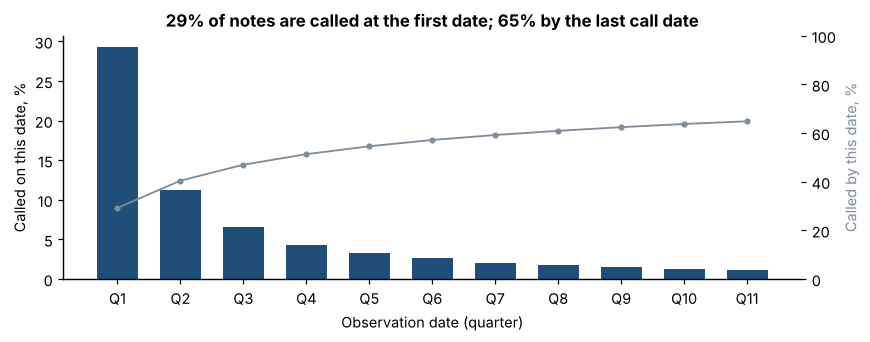

In [16]:
cum = np.cumsum(res.call_prob)
fig, ax = plt.subplots(figsize=(8, 3.2))
labels = [f"Q{k + 1}" for k in range(ts.n_obs)]
ax.bar(labels[:-1], 100 * res.call_prob[:-1], color=ACCENT, width=0.65)
ax2 = ax.twinx()
ax2.plot(labels[:-1], 100 * cum[:-1], color=GREYS[0], marker="o", ms=3, lw=1.2)
ax2.set_ylim(0, 100); ax2.spines["top"].set_visible(False); ax2.set_ylabel("Called by this date, %", color=GREYS[0])
ax.set(title=f"{pct(res.call_prob[0], 0)} of notes are called at the first date; {pct(cum[-2], 0)} by the last call date",
       xlabel="Observation date (quarter)", ylabel="Called on this date, %")
plt.tight_layout()

In [17]:
outcomes = pd.Series({
    "Called early": pct(1 - res.maturity_prob),
    "Runs to maturity, capital back": pct(res.maturity_prob - res.loss_prob),
    "Runs to maturity, capital loss": pct(res.loss_prob),
    "Average repayment when there is a loss": f"{res.loss_given_loss:.1f} per 100",
    "Expected life": f"{res.expected_life:.2f} years",
    "Coupons received, on average": f"{res.expected_coupons:.1f} of {ts.n_obs} quarters",
}, name="Outcome")
outcomes.to_frame()

,Outcome
Called early,64.8%
"Runs to maturity, capital back",24.1%
"Runs to maturity, capital loss",11.1%
Average repayment when there is a loss,49.8 per 100
Expected life,1.52 years
"Coupons received, on average",5.1 of 12 quarters


## 3. Risk and structuring

### What moves the price

Sensitivities by bump and reprice: each input is moved up and down, the note is repriced on the **same** random
numbers, and the difference is halved. Reusing the random numbers removes most of the simulation noise from the
difference.

In [18]:
from autocall import risk as R

g = R.greeks(ts, mkt, snap.names)
show = g.copy()
show["delta per 1% move"] = show["delta per 1% move"].map(lambda x: f"{x:+.3f}")
show["equivalent exposure, % of notional"] = show["equivalent exposure, % of notional"].map(lambda x: f"{x:.1f}%")
show["vega per vol point"] = show["vega per vol point"].map(lambda x: f"{x:+.3f}")
show

,delta per 1% move,"equivalent exposure, % of notional",vega per vol point
index,,,
S&P 500,+0.017,1.7%,-0.151
Euro Stoxx 50,+0.063,6.3%,-0.270
Nikkei 225,+0.159,15.9%,-0.445
All three together,+0.242,24.2%,-0.868


In [19]:
d = g.loc[snap.names, "delta per 1% move"]
v_all = g.loc["All three together", "vega per vol point"]
print(f"The note behaves most like the {d.idxmax()} ({d.max() / d.sum():.0%} of the total delta): the most volatile")
print("index is the one most likely to end up the worst, so it drives the payoff.")
print(f"Vega is negative ({v_all:+.2f} per vol point for all three): the investor has sold protection against large falls,")
print("so more volatility makes the note worth less. The issuer, on the other side of the trade, is long volatility.")

The note behaves most like the Nikkei 225 (66% of the total delta): the most volatile
index is the one most likely to end up the worst, so it drives the payoff.
Vega is negative (-0.87 per vol point for all three): the investor has sold protection against large falls,
so more volatility makes the note worth less. The issuer, on the other side of the trade, is long volatility.


+0.10 on every correlation adds 0.22 to the fair value. When the indices move together, one index is less
likely to fall far on its own, so the worst-of suffers less. The investor is long correlation; the issuer, who sold
the note, is short it. Correlation cannot be hedged precisely with listed instruments, so desks hold a reserve for it.


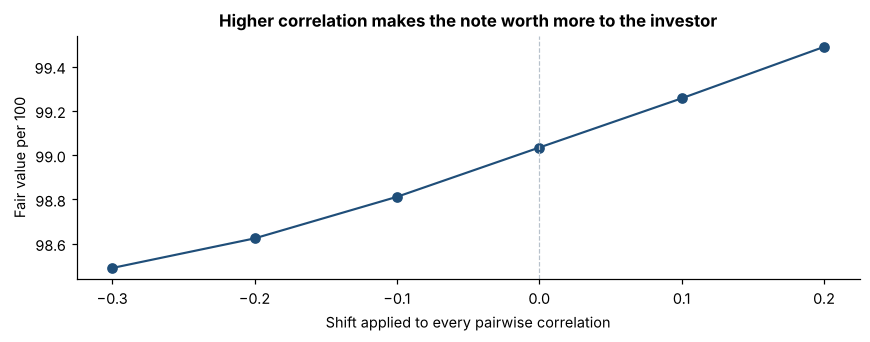

In [20]:
cs = R.correlation_sensitivity(ts, mkt)
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(cs.index, cs.values, color=ACCENT, marker="o", lw=1.4)
ax.axvline(0, color=GREYS[1], lw=0.8, ls="--")
ax.set(title="Higher correlation makes the note worth more to the investor",
       xlabel="Shift applied to every pairwise correlation", ylabel="Fair value per 100")
plt.tight_layout()
step = cs.loc[0.1] - cs.loc[0.0]
print(f"+0.10 on every correlation adds {step:.2f} to the fair value. When the indices move together, one index is less")
print("likely to fall far on its own, so the worst-of suffers less. The investor is long correlation; the issuer, who sold")
print("the note, is short it. Correlation cannot be hedged precisely with listed instruments, so desks hold a reserve for it.")

### The structurer's question: what coupon can we offer?

The bank chooses a margin, then solves for the coupon that makes fair value equal to the issue price minus that margin.
A 2-point margin is used below as an illustration; real margins depend on the client, the distribution channel and
hedging costs.

In [21]:
MARGIN = 2.0
z_fc = mc.normals(mc.DEFAULT_PATHS, ts.n_obs, len(snap.names))
fc = pd.Series({m: R.fair_coupon(ts, mkt, m, z=z_fc) for m in (0.0, 1.0, 2.0, 3.0)})
print(f"With a {MARGIN:.0f}-point margin the note can pay {fc[MARGIN]:.2%} a year; at zero margin, {fc[0.0]:.2%}.")
fc.map(lambda c: f"{c:.2%}").rename_axis("issuer margin, points per 100").to_frame("fair annual coupon")

With a 2-point margin the note can pay 7.15% a year; at zero margin, 8.80%.


,fair annual coupon
"issuer margin, points per 100",
0.0,8.80%
1.0,7.97%
2.0,7.15%
3.0,6.32%


Moving the barrier from 60% to 50% costs the investor 2.07% a year of coupon; raising it to 70% adds 2.05%.
A lower call trigger ends the note earlier, so there are fewer coupon periods to fund: at 90% the fair
coupon is 5.16%, against 7.15% at 100%.


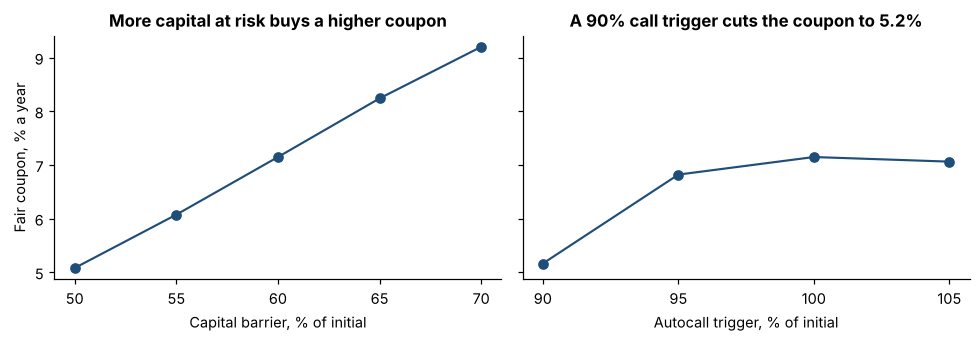

In [22]:
ki = R.coupon_grid(ts, mkt, MARGIN, "ki_barrier", [0.50, 0.55, 0.60, 0.65, 0.70])
cb = R.coupon_grid(ts, mkt, MARGIN, "autocall_trigger", [0.90, 0.95, 1.00, 1.05])
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), sharey=True)
axes[0].plot(100 * ki.index, 100 * ki.values, color=ACCENT, marker="o", lw=1.4)
axes[0].set(title="More capital at risk buys a higher coupon", xlabel="Capital barrier, % of initial", ylabel="Fair coupon, % a year")
axes[0].set_xticks(100 * ki.index)
axes[1].plot(100 * cb.index, 100 * cb.values, color=ACCENT, marker="o", lw=1.4)
axes[1].set(title=f"A {cb.index[0]:.0%} call trigger cuts the coupon to {cb.iloc[0]:.1%}", xlabel="Autocall trigger, % of initial")
axes[1].set_xticks(100 * cb.index)
plt.tight_layout()
print(f"Moving the barrier from 60% to 50% costs the investor {ki[0.60] - ki[0.50]:.2%} a year of coupon;"
      f" raising it to 70% adds {ki[0.70] - ki[0.60]:.2%}.")
print(f"A lower call trigger ends the note earlier, so there are fewer coupon periods to fund: at {cb.index[0]:.0%} the fair")
print(f"coupon is {cb.iloc[0]:.2%}, against {cb.loc[1.0]:.2%} at {1.0:.0%}.")